<a href="https://colab.research.google.com/github/akatwrk/DeeplearningExp/blob/main/exp_3a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import zipfile
import os
import shutil

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Extract dogs_vs_cats_subset (1) (1).zip to local Colab storage
zip_file = "/content/drive/MyDrive/deeplearning/dogs_vs_cats_subset (1) (1).zip"
extract_path = "/content/dogs_vs_cats_subset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Extracted contents:", os.listdir(extract_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset extracted successfully!
Extracted contents: ['dogs_vs_cats_subset']


In [ ]:
base_dir = "/content/dogs_vs_cats_subset/dogs_vs_cats_subset"

train_dir = os.path.join(base_dir, "train")
val_dir   = os.path.join(base_dir, "val")
test_dir  = os.path.join(base_dir, "test")

In [ ]:
import os
import shutil

base_path = "/content/dogs_vs_cats_subset/dogs_vs_cats_subset"

for folder in ["train", "val"]:
    folder_path = os.path.join(base_path, folder)

    os.makedirs(os.path.join(folder_path, "cats"), exist_ok=True)
    os.makedirs(os.path.join(folder_path, "dogs"), exist_ok=True)

    for file in os.listdir(folder_path):
        src = os.path.join(folder_path, file)

        if not os.path.isfile(src):
            continue

        if file.startswith("cat"):
            shutil.move(src, os.path.join(folder_path, "cats", file))
        elif file.startswith("dog"):
            shutil.move(src, os.path.join(folder_path, "dogs", file))

print("Train and Validation folders organized successfully!")

Train and Validation folders organized successfully!


In [ ]:
base_path = "/content/dogs_vs_cats_subset/dogs_vs_cats_subset"

for root, dirs, files in os.walk(base_path):
    if files:
        print(root)
        print(files[:5])

/content/dogs_vs_cats_subset/dogs_vs_cats_subset
['CDLA-Permissive-2.0.pdf']
/content/dogs_vs_cats_subset/dogs_vs_cats_subset/val/cats
['cat.12080.jpg', 'cat.12096.jpg', 'cat.12077.jpg', 'cat.12039.jpg', 'cat.12035.jpg']
/content/dogs_vs_cats_subset/dogs_vs_cats_subset/val/dogs
['dog.12080.jpg', 'dog.12057.jpg', 'dog.12083.jpg', 'dog.12030.jpg', 'dog.12026.jpg']
/content/dogs_vs_cats_subset/dogs_vs_cats_subset/test
['58.jpg', '50.jpg', '29.jpg', '83.jpg', '77.jpg']
/content/dogs_vs_cats_subset/dogs_vs_cats_subset/train/cats
['cat.348.jpg', 'cat.314.jpg', 'cat.457.jpg', 'cat.60.jpg', 'cat.278.jpg']
/content/dogs_vs_cats_subset/dogs_vs_cats_subset/train/dogs
['dog.491.jpg', 'dog.193.jpg', 'dog.152.jpg', 'dog.282.jpg', 'dog.57.jpg']


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
Conv2D,
MaxPooling2D,
Flatten,
Dense,
Dropout
)

In [ ]:
train_dir = "/content/dogs_vs_cats_subset/dogs_vs_cats_subset/train"
val_dir = "/content/dogs_vs_cats_subset/dogs_vs_cats_subset/val"

IMG_SIZE = (150, 150)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    rescale=1./255
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=True
)

Found 1000 images belonging to 2 classes.


In [ ]:
val_generator = val_datagen.flow_from_directory(
val_dir,
target_size=IMG_SIZE,
batch_size=BATCH_SIZE,
class_mode="binary",
shuffle=False
)

Found 200 images belonging to 2 classes.


In [ ]:
best_model = tuner.get_best_models(1)[0]
early_stop = EarlyStopping(
monitor="val_loss",
patience=3,
restore_best_weights=True
)
history = best_model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

In [ ]:
import os

val_path = "/content/dogs_vs_cats_subset/dogs_vs_cats_subset/val"
count = 0
for root, dirs, files in os.walk(val_path):
    count += len([f for f in files if f.endswith(".jpg")])
print("Total Validation Images:", count)

Total Validation Images: 200


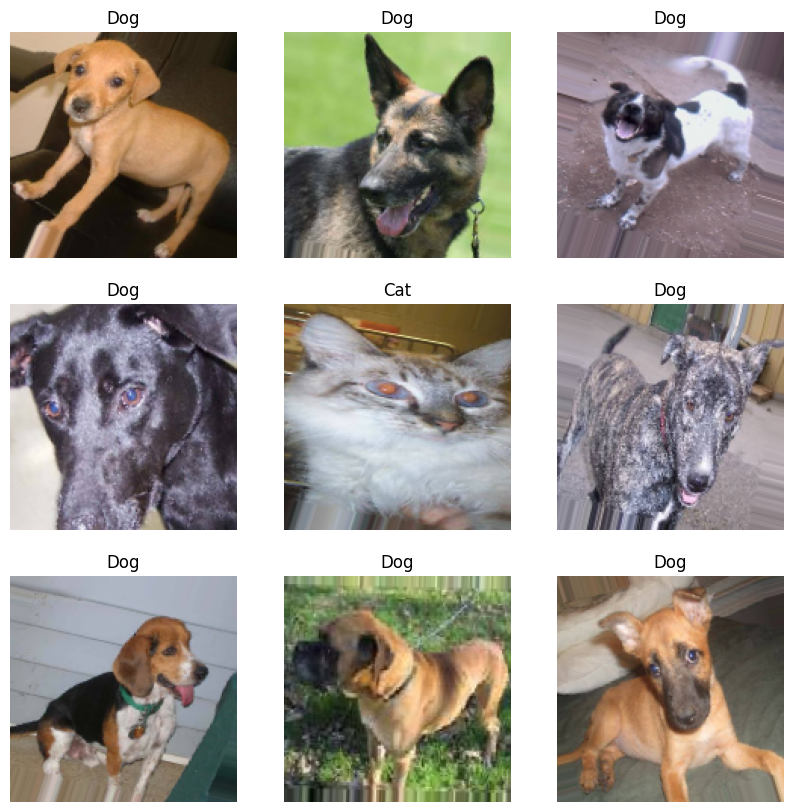

In [ ]:
images, labels = next(train_generator)
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    plt.title("Dog" if labels[i] == 1 else "Cat")
    plt.axis("off")
plt.show()

In [ ]:
model=Sequential([
tf.keras.Input(shape=(150,150,3)),
Conv2D(32,(3,3),activation="relu"),
MaxPooling2D(),
Conv2D(64,(3,3),activation="relu"),
MaxPooling2D(),
Conv2D(128,(3,3),activation="relu"),
MaxPooling2D(),
Flatten(),
Dense(128,activation="relu"),
Dropout(0.5),
Dense(1,activation="sigmoid")
])
model.compile(
optimizer="adam",
loss="binary_crossentropy",
metrics=["accuracy"]
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(
monitor="val_loss",
patience=3,
restore_best_weights=True
)
history = model.fit(
train_generator,
validation_data=val_generator,
epochs=15,
callbacks=[early_stop]
)

Epoch 1/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 31s 642ms/step - accuracy: 0.5170 - loss: 0.7174 - val_accuracy: 0.5050 - val_loss: 0.6913
Epoch 2/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 12s 361ms/step - accuracy: 0.5430 - loss: 0.6897 - val_accuracy: 0.5100 - val_loss: 0.6801
Epoch 3/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 270ms/step - accuracy: 0.5720 - loss: 0.6804 - val_accuracy: 0.6600 - val_loss: 0.6563
Epoch 4/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 215ms/step - accuracy: 0.5890 - loss: 0.6727 - val_accuracy: 0.5800 - val_loss: 0.6999
Epoch 5/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 276ms/step - accuracy: 0.6120 - loss: 0.6732 - val_accuracy: 0.5950 - val_loss: 0.6677
Epoch 6/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 228ms/step - accuracy: 0.6020 - loss: 0.6463 - val_accuracy: 0.6200 - val_loss: 0.6677


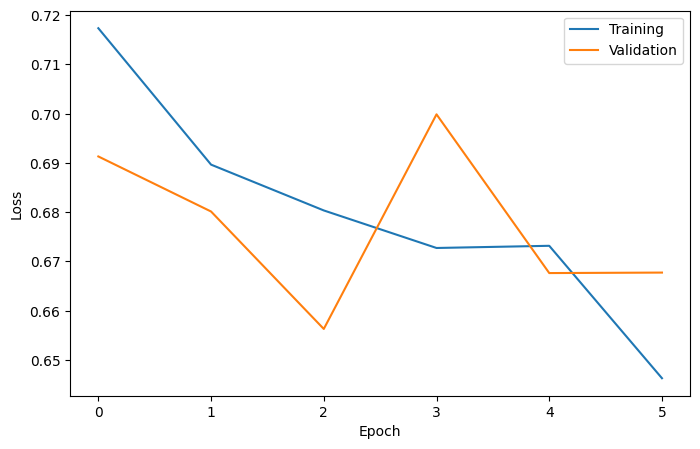

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"],label="Training")
plt.plot(history.history["val_loss"],label="Validation")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
val_generator.reset()
pred=model.predict(val_generator)
pred=(pred>0.5).astype(int)
cm=confusion_matrix(val_generator.classes,pred)
print(cm)
print(classification_report(
val_generator.classes,
pred,
target_names=["Cat","Dog"]
))

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 147ms/step
[[43 57]
 [11 89]]
              precision    recall  f1-score   support

         Cat       0.80      0.43      0.56       100
         Dog       0.61      0.89      0.72       100

    accuracy                           0.66       200
   macro avg       0.70      0.66      0.64       200
weighted avg       0.70      0.66      0.64       200



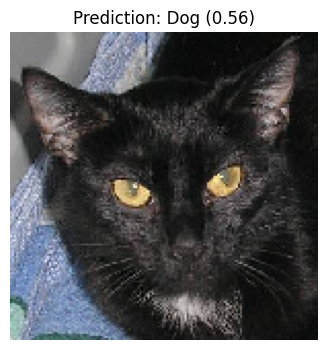

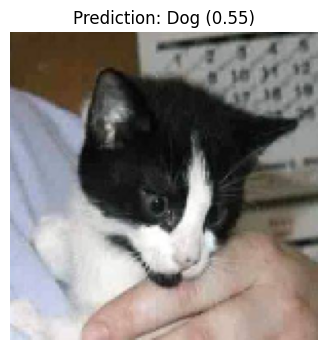

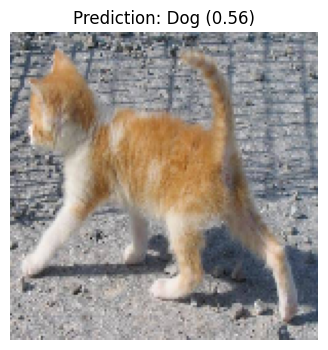

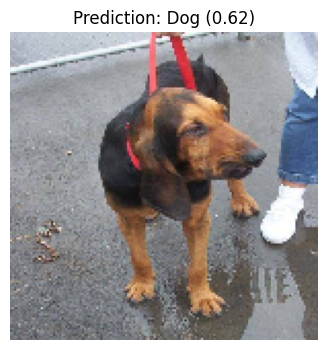

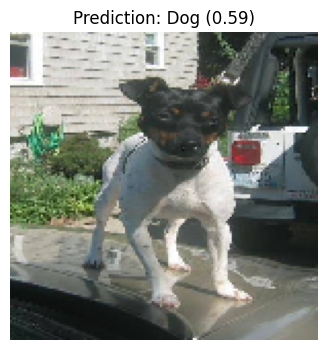

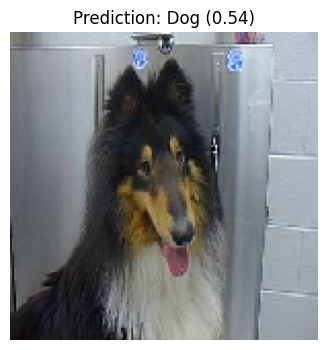

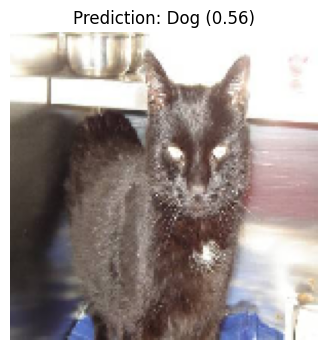

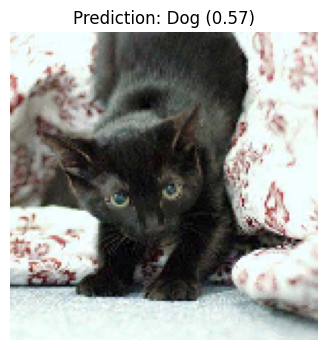

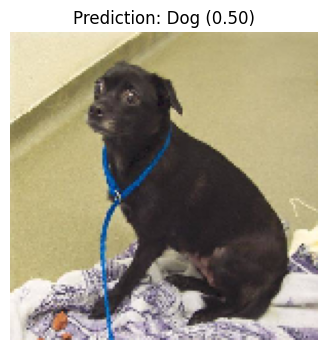

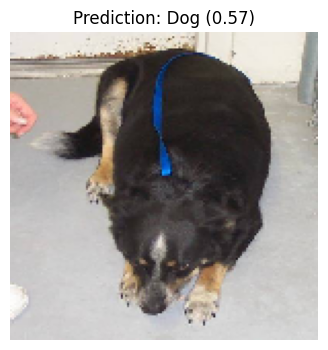

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

test_path = "/content/dogs_vs_cats_subset/dogs_vs_cats_subset/test"

files = [f for f in os.listdir(test_path) if os.path.isfile(os.path.join(test_path, f))]

for f in files[:10]:
    img = image.load_img(
        os.path.join(test_path, f),
        target_size=(150, 150)
    )

    x = image.img_to_array(img)
    x = x / 255.0
    x = np.expand_dims(x, axis=0)

    pred = model.predict(x, verbose=0)
    label = "Dog" if pred[0][0] > 0.5 else "Cat"

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(f"Prediction: {label} ({pred[0][0]:.2f})")
    plt.axis("off")
    plt.show()